# Recovering the results of Yang+26 through an independent catalog matching search

This notebook reproduces the archival GW–SN matching analysis described in the paper Yang+26 "A temporally clustered gravitational wave pair and a Type IIb supernova", using only public data:

* **ZTF Bright Transient Survey (BTS)** catalogue; **GraceDB** (public superevents, alert notices, BAYESTAR / LALInference / Bilby / cWB sky maps)

1. We assemble the **SN sample** from BTS, with redshifts converted to luminosity distance using Planck18 cosmology
2. We assemble the **GW sample** from GraceDB (cross-checking sample size and source-class annotations).
3. For the GW sample, we retrieve the **BAYESTAR localisation products**. These are resampled and cached. A clean run of the notebook without this cache rebuilds it from scratch. 
4. We then follow Yang+ procedure of **Spatial matching** (SN pixel inside the GW 90% credible sky region)
5. **Temporal matching** based on the SN time-delay criterion of Yang+ ($10 < \Delta t_{\rm rest} < 30$ d)
7. **Identification of SN 2019rsq / S190910d–S190910h**


**Dependencies:** `numpy scipy astropy pandas matplotlib requests ligo-gracedb`. **No `ligo.skymap`, no `healpy`**: the HEALPix operations needed are implemented below in numpy thanks to assistance from Claude. For some reason ligo.skymap borks my computer, and I'm not willing to nuke another Python distro. 

**Cache:** Everything downloaded is stored in `CACHE_DIR`. If you have the pre-filled cache archive (`data_cache.tar.gz`), extract it next to this notebook *before running*. Steps 2–3 will skip GraceDB downloads, and the BTS catalogue is read from disk.

**Runtime (warm cache):** about 10 min. Step 3b (resampling 248 maps) takes ~3–4 min the first time; Step 5 (distance test on ~25k sky matches) a few minutes; the O3 ranking in Step 7b ~2 min and ~1.5 GB of memory. Without the cache, downloads add ~20–40 min.

**Conventions.** Times are GPS (GraceDB) or JD (BTS: `peakt` = JD − 2458000). Maps are handled in **NESTED** ordering throughout. "Significant" alerts: O3 had one public stream. O4 public alerts are split into significant (`SIGNIF_LOCKED`) and low-significance. We ignore low-significance events

In [2]:
import os, re, json, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time
from astropy.coordinates import SkyCoord
from astropy.cosmology import Planck18
import astropy.units as u
from scipy.special import ndtr
from concurrent.futures import ThreadPoolExecutor
from ligo.gracedb.rest import GraceDb

CACHE_DIR = os.path.abspath('data_cache')
os.makedirs(CACHE_DIR, exist_ok=True)
g = GraceDb()

# figure style
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
                     'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Serif'],
                     'font.size': 18, 'legend.numpoints': 1})

def cached(name, fn):
    '''JSON cache: return cached value if present, else compute, store and return.'''
    p = os.path.join(CACHE_DIR, name)
    if os.path.exists(p):
        return json.load(open(p))
    out = fn(); json.dump(out, open(p, 'w')); return out

def record(n, statement, claim, found, verdict, notes=''):
    RESULTS[n] = dict(statement=statement, claim=claim, found=found, verdict=verdict, notes=notes)
    print(f'[{n}] {verdict}\n    found: {found}')

## HEALPix helpers (numpy only)

Pixel lookup (`ang2pix_nest`), RING→NESTED conversion, multi-order (`UNIQ`) decoding, a FITS reader that handles both multi-order and flat maps, and `rasterize`. `rasterize` resamples to a fixed order by **replicating** coarser tiles and **averaging** finer ones. This is exactly what `ligo.skymap.moc.rasterize` and `healpy.ud_grade` (default settings) do, for the probability density and for the `DISTMU/DISTSIGMA/DISTNORM` layers alike. Created with assistance from Claude.ai

In [3]:
import numpy as np
from astropy.io import fits

_JPLL = np.array([1, 3, 5, 7, 0, 2, 4, 6, 1, 3, 5, 7], dtype=np.int64)


def _spread(v, order):
    out = np.zeros_like(v)
    for b in range(order):
        out |= ((v >> b) & 1) << (2 * b)
    return out


def _isqrt(x):
    r = np.floor(np.sqrt(x.astype(np.float64))).astype(np.int64)
    r -= (r * r > x)
    r += ((r + 1) * (r + 1) <= x)
    return r


def ang2pix_nest(nside, ra_deg, dec_deg):
    """NESTED pixel index for (RA, Dec) in degrees (port of HEALPix loc2pix)."""
    order = int(np.log2(nside))
    z = np.sin(np.deg2rad(np.asarray(dec_deg, float)))
    za = np.abs(z)
    tt = np.mod(np.deg2rad(np.asarray(ra_deg, float)), 2 * np.pi) / (0.5 * np.pi)
    face = np.empty(z.shape, np.int64); ix = np.empty(z.shape, np.int64); iy = np.empty(z.shape, np.int64)
    eq = za <= 2.0 / 3.0
    # equatorial
    t1 = nside * (0.5 + tt[eq]); t2 = nside * z[eq] * 0.75
    jp = (t1 - t2).astype(np.int64); jm = (t1 + t2).astype(np.int64)
    ifp, ifm = jp >> order, jm >> order
    face[eq] = np.where(ifp == ifm, ifp | 4, np.where(ifp < ifm, ifp, ifm + 8))
    ix[eq] = jm & (nside - 1); iy[eq] = nside - (jp & (nside - 1)) - 1
    # polar caps
    pc = ~eq
    ntt = np.minimum(3, tt[pc].astype(np.int64)); tp = tt[pc] - ntt
    tmp = nside * np.sqrt(3 * (1 - za[pc]))
    jp = np.minimum((tp * tmp).astype(np.int64), nside - 1)
    jm = np.minimum(((1 - tp) * tmp).astype(np.int64), nside - 1)
    north = z[pc] >= 0
    face[pc] = np.where(north, ntt, ntt + 8)
    ix[pc] = np.where(north, nside - jm - 1, jp)
    iy[pc] = np.where(north, nside - jp - 1, jm)
    return (face << (2 * order)) + _spread(ix, order) + (_spread(iy, order) << 1)


def ring2nest(nside, ipring):
    """RING -> NESTED pixel index (port of healpix_base ring2xyf + xyf2nest)."""
    order = int(np.log2(nside))
    pix = np.asarray(ipring, dtype=np.int64)
    npix = 12 * nside * nside; ncap = 2 * nside * (nside - 1); nl2 = 2 * nside
    iring = np.empty_like(pix); iphi = np.empty_like(pix)
    kshift = np.zeros_like(pix); nr = np.empty_like(pix); face = np.empty_like(pix)
    n = pix < ncap
    ir = (1 + _isqrt(1 + 2 * pix[n])) >> 1
    iring[n] = ir; iphi[n] = pix[n] + 1 - 2 * ir * (ir - 1); nr[n] = ir; face[n] = (iphi[n] - 1) // ir
    e = (pix >= ncap) & (pix < npix - ncap)
    ip = pix[e] - ncap; tmp = ip // (4 * nside)
    iring[e] = tmp + nside; iphi[e] = ip - tmp * 4 * nside + 1
    kshift[e] = (iring[e] + nside) & 1; nr[e] = nside
    ire = tmp + 1; irm = nl2 + 1 - tmp
    ifm = (iphi[e] - (ire >> 1) + nside - 1) // nside
    ifp = (iphi[e] - (irm >> 1) + nside - 1) // nside
    face[e] = np.where(ifp == ifm, ifp | 4, np.where(ifp < ifm, ifp, ifm + 8))
    s = pix >= npix - ncap
    ip = npix - pix[s]; ir = (1 + _isqrt(2 * ip - 1)) >> 1
    iphi[s] = 4 * ir + 1 - (ip - 2 * ir * (ir - 1)); nr[s] = ir
    iring[s] = 2 * nl2 - ir; face[s] = 8 + (iphi[s] - 1) // ir
    irt = iring - (2 + (face >> 2)) * nside + 1
    ipt = 2 * iphi - _JPLL[face] * nr - kshift - 1
    ipt = np.where(ipt >= nl2, ipt - 8 * nside, ipt)
    ix = (ipt - irt) >> 1; iy = (-ipt - irt) >> 1
    return (face << (2 * order)) + _spread(ix, order) + (_spread(iy, order) << 1)


def uniq_to_order_ipix(uniq):
    uniq = np.asarray(uniq, dtype=np.int64)
    order = (np.floor(np.log2(uniq.astype(np.float64)) / 2) - 1).astype(np.int64)
    order -= (4 * 4**order > uniq)
    order += (4 * 4**(order + 1) <= uniq)
    return order, uniq - 4 * 4**order


COLS = ('PROBDENSITY', 'DISTMU', 'DISTSIGMA', 'DISTNORM')


def read_map_tiles(path):
    """Return (order, nested ipix, {col: values}) for a multi-order or flat FITS sky map.
    Values are per-steradian densities for PROBDENSITY; DIST* as stored."""
    with fits.open(path) as h:
        hdr, d = h[1].header, h[1].data
        names = d.columns.names
        if 'UNIQ' in names:
            order, ipix = uniq_to_order_ipix(np.asarray(d['UNIQ']).ravel())
            vals = {c: np.asarray(d[c], dtype=np.float64).ravel() for c in COLS if c in names}
            return order, ipix, vals
        nside = int(hdr['NSIDE']); npix = 12 * nside * nside
        pname = next((c for c in ('PROB', 'PROBABILITY') if c in names), names[0])
        prob = np.asarray(d[pname], dtype=np.float64).ravel()
        vals = {'PROBDENSITY': prob / (4 * np.pi / npix)}
        for c in COLS[1:]:
            if c in names:
                vals[c] = np.asarray(d[c], dtype=np.float64).ravel()
        ipix = np.arange(npix, dtype=np.int64)
        if str(hdr.get('ORDERING', 'RING')).strip().upper().startswith('RING'):
            ipix = ring2nest(nside, ipix)
        return np.full(npix, int(np.log2(nside)), np.int64), ipix, vals


def rasterize(order, ipix, vals, target_order):
    """Fixed-order NESTED arrays. Coarser tiles are replicated; finer tiles are averaged
    over children (the same operation as ligo.skymap.moc.rasterize / healpy.ud_grade)."""
    npix = 12 * 4**target_order
    out = {c: np.zeros(npix) for c in vals}
    coarse = order <= target_order
    if coarse.any():
        d = target_order - order[coarse]
        start = ipix[coarse] << (2 * d); n = (1 << (2 * d))
        idx = np.repeat(start, n) + (np.arange(n.sum()) - np.repeat(np.cumsum(n) - n, n))
        for c, v in vals.items():
            out[c][idx] = np.repeat(v[coarse], n)
    fine = ~coarse
    if fine.any():
        d = order[fine] - target_order
        parent = ipix[fine] >> (2 * d); w = 1.0 / (1 << (2 * d))
        for c, v in vals.items():
            with np.errstate(invalid='ignore', over='ignore'):
                np.add.at(out[c], parent, v[fine] * w)
    return out


def tile_area(order):
    return 4 * np.pi / (12 * 4.0**np.asarray(order))

## Data access helpers (GraceDB)

* `all_public()`: every public superevent from the start of O3 (2019-04-01 15:00 UTC) to the end of O4b (2025-01-28 17:00 UTC).
* `retracted(sid)`: whether a retraction notice (VOEvent type `RE`) exists. O3 had no `RETRACTED` label, with retractions flagged as `ADVNO`.
* `classifications(sid)`: source-class probabilities from every readable (non-retraction) alert notice. A few O3 notice XMLs are not publicly exposed and are skipped.
* `files(sid)`, `local_map(sid, fname)`: file listing and cached download.

In [4]:
O3_START, O4B_END = 1238166018, 1422118818 #GPS start and end time, pulled from GWOSC
RUNS = {'O3a': (1238166018, 1253977218), 'O3b': (1256655618, 1269363618),
        'O4a': (1368975618, 1389456018), 'O4b': (1396796418, 1422118818)}

def run_of(t):
    return next((k for k, (a, b) in RUNS.items() if a <= t <= b), 'between runs')

def all_public():
    return cached('all_public_O3_O4b.json',
                  lambda: list(g.superevents(query=f'is_public: True t_0: {O3_START} .. {O4B_END}')))

def is_significant(s):
    return s['t_0'] < 1.3e9 or 'SIGNIF_LOCKED' in s['labels']     # O3: single stream

def retracted(sid):
    return cached(f'retracted_{sid}.json',
                  lambda: any(v['voevent_type'] == 'RE' for v in g.voevents(sid).json()['voevents']))

CLASS_KEYS = ['BNS', 'NSBH', 'BBH', 'MassGap', 'Terrestrial', 'HasNS', 'HasRemnant', 'HasMassGap']

def classifications(sid):
    def f():
        out = []
        for v in sorted(g.voevents(sid).json()['voevents'], key=lambda v: v['N']):
            if v['voevent_type'] == 'RE':
                continue
            try:
                xml = g.files(sid, v['filename']).read().decode()
            except Exception:
                continue
            c = {k: float(m.group(1)) for k in CLASS_KEYS
                 for m in [re.search(rf'name="{k}"[^>]*value="([^"]+)"', xml)] if m}
            if 'BNS' in c or 'NSBH' in c:
                out.append([v['N'], v['voevent_type'], c])
        return out
    return cached(f'classes_{sid}.json', f)

def files(sid):
    return cached(f'files_{sid}.json', lambda: list(g.files(sid).json()))

def local_map(sid, fname):
    p = os.path.join(CACHE_DIR, f'{sid}__{fname}')
    if not os.path.exists(p):
        data = g.files(sid, fname).read()   # download before creating the file, so a failed download leaves nothing behind
        open(p, 'wb').write(data)
    return p

## Step 1: Stripped-envelope SN sample (ZTF BTS) and luminosity distances

Yang+ use the public ZTF-BTS catalog to assemble a sample of stripped-envelope supernovae. We follow their procedure and select events with spectroscopic classifications "consistent with SE explosions, including Types IIb, Ib, Ic and closely related subtypes such as Ic-BL, and required the source information needed for the spatial and distance matching described below."

We limit our sample selection to the interval stated in Yang+: from the beginning of O3 on 2019 April 1 through 2025 February 27, 30 days beyond the end of O4b.

We apply **no quality cut and no magnitude limit**.

**Distances.** We assume the standard Planck 2018 cosmology (`astropy.cosmology.Planck18`): $d_L = d_L(z_{\rm SN})$.

In [10]:
BTS_URL = ('https://sites.astro.caltech.edu/ztf/bts/explorer.php?f=s&format=csv&subsample=all'
           '&showdiscdate=y&showsavedate=y&showpeakdate=y&showlastdate=y')
bts_path = os.path.join(CACHE_DIR, 'bts_all.csv')
if not os.path.exists(bts_path):
    import requests
    print('downloading', BTS_URL)
    r = requests.get(BTS_URL, timeout=300); r.raise_for_status()
    open(bts_path, 'w').write(r.text)
    
BTS = pd.read_csv(bts_path)
BTS['z'] = pd.to_numeric(BTS['redshift'], errors='coerce')
BTS['tpeak_jd'] = BTS['peakt'] + 2458000
c = SkyCoord(BTS['RA'].values, BTS['Dec'].values, unit=(u.hourangle, u.deg))
BTS['ra_deg'], BTS['dec_deg'] = c.ra.deg, c.dec.deg

# convert BTS redshifts to luminosity distances
BTS['dl_mpc'] = np.nan
_hasz = BTS['z'].notna().values
BTS.loc[_hasz, 'dl_mpc'] = Planck18.luminosity_distance(BTS.loc[_hasz, 'z'].values).to_value(u.Mpc)

print(len(BTS), 'BTS entries; peak dates', Time(BTS.tpeak_jd.min(), format='jd').iso[:10], '→', 
      Time(BTS.tpeak_jd.max(), format='jd').iso[:10])


# Supernova types in the sample: Ib, Ic and subtypes, IIb, interacting Ibn/Icn, and SLSN-I
SE_CORE = ['SN Ic', 'SN Ib', 'SN IIb', 'SN Ic-BL', 'SN Ib/c', 'SN Ib-pec', 'SN Ic-pec']
SE_INT  = ['SN Ibn', 'SN Icn']
SE_SLSN = ['SLSN-I']
SE_ALL  = SE_CORE + SE_INT + SE_SLSN

# 2. Date window, "from 2019 April 1 through 2025 February 27"
T_SN_START = Time('2019-04-01T00:00:00', scale='utc').jd
T_SN_END   = Time('2025-02-28T00:00:00', scale='utc').jd
DATE_COL   = 'tpeak_jd'

#Require position and redshift information for matching
has_info = BTS.z.notna() & np.isfinite(BTS.ra_deg) & np.isfinite(BTS.dec_deg)

is_se  = BTS.type.isin(SE_ALL)
in_win = (BTS[DATE_COL] >= T_SN_START) & (BTS[DATE_COL] < T_SN_END)

print(f'SE types, all dates:        {is_se.sum()}')
print(f'  + in window ({DATE_COL}):  {(is_se & in_win).sum()}')
print(f'  + has z and position:     {(is_se & in_win & has_info).sum()}')

SN_SAMPLE = BTS[is_se & in_win & has_info].reset_index(drop=True)
print(f'\nSN sample: {len(SN_SAMPLE)} (paper: 676), Type IIb: {(SN_SAMPLE.type == "SN IIb").sum()} (paper: 122)')
print(SN_SAMPLE.type.value_counts().to_string())

pk  = BTS.tpeak_jd.values
iib = (BTS.type == 'SN IIb').values

10988 BTS entries; peak dates 2018-04-02 → 2026-02-08
SE types, all dates:        777
  + in window (tpeak_jd):  601
  + has z and position:     601

SN sample: 601 (paper: 676), Type IIb: 107 (paper: 122)
type
SN Ic        153
SN Ib        130
SN IIb       107
SLSN-I        69
SN Ic-BL      68
SN Ibn        33
SN Ib/c       32
SN Icn         5
SN Ib-pec      3
SN Ic-pec      1


In [11]:
# For a fair comparison and to replicate the subsequent statistics, we search for a sample window that gives the required number of SNe and of the IIb subtype. 

starts = np.arange(Time('2018-03-01').jd, Time('2019-12-31').jd); ends = np.arange(Time('2025-01-01').jd, Time('2026-03-01').jd)
for name, types in {'core+Ibn/Icn': SE_CORE + SE_INT, 'BTS SESN (incl. SLSN-I)': SE_CORE + SE_INT + ['SLSN-I']}.items():
    tt = np.sort(pk[BTS.type.isin(types).values]); ti = np.sort(pk[iib])
    N = np.searchsorted(tt, ends)[None, :] - np.searchsorted(tt, starts)[:, None]
    Ni = np.searchsorted(ti, ends)[None, :] - np.searchsorted(ti, starts)[:, None]
    hit = np.argwhere((N == 676) & (Ni == 122))
    eg = [f'{Time(starts[i], format="jd").iso[:10]} → {Time(ends[j], format="jd").iso[:10]}' for i, j in hit[::max(1, len(hit) // 4)][:4]]
    print(f'{name}: {len(hit)} exact windows', eg)

# Two SN samples carried forward
SN = {'Lasky+': SN_SAMPLE,
      'Yang+':   BTS[BTS.type.isin(SE_ALL).values & (pk >= Time('2019-01-21').jd) & (pk < Time('2025-10-07').jd)].reset_index(drop=True)}
print({k: (len(v), int((v.type == 'SN IIb').sum())) for k, v in SN.items()})

core+Ibn/Icn: 0 exact windows []
BTS SESN (incl. SLSN-I): 145 exact windows ['2018-06-02 → 2025-02-19', '2018-11-07 → 2025-07-13', '2018-11-12 → 2025-08-04', '2018-12-07 → 2025-09-08']
{'Lasky+': (601, 107), 'Yang+': (676, 122)}


**Notes.**
* Using the information given in the paper, we assemble a sample of **601** SNe, with **107** IIb
*  **Lasky+** is the sample of SNe we assembled. **Yang+** is the sample within the window identified in the cell above that can replicate the number of SNe, and of SN IIb stated in Yang+

## Step 2: GW sample from GraceDB

### 2a. Sample size

We now assemble the GW sample according to the instructions in Yang+, querying all superevents from O3-O4b. 

In [12]:
ses = all_public()
sig = [s for s in ses if is_significant(s)]
with ThreadPoolExecutor(8) as ex:
    ret = dict(zip([s['superevent_id'] for s in sig], ex.map(retracted, [s['superevent_id'] for s in sig])))
SAMPLE = sorted([s for s in sig if not ret[s['superevent_id']]], key=lambda s: s['t_0'])
SID = [s['superevent_id'] for s in SAMPLE]
T0 = {s['superevent_id']: s['t_0'] for s in SAMPLE}

by_run = pd.Series([run_of(s['t_0']) for s in SAMPLE]).value_counts()
between = [s['superevent_id'] for s in SAMPLE if run_of(s['t_0']) == 'between runs']
advno = sum('ADVNO' in s['labels'] for s in sig)
print(f'{len(ses)} public superevents; {len(ses) - len(sig)} O4 low-significance; {len(sig)} significant/O3')
print(f'{sum(ret.values())} retracted (ADVNO label count: {advno}); non-retracted: {len(SAMPLE)}')
print(by_run.to_string()); print('between official run windows:', between)

3649 public superevents; 3364 O4 low-significance; 285 significant/O3
37 retracted (ADVNO label count: 37); non-retracted: 248
O4b             105
O4a              82
O3a              33
O3b              23
between runs      5
between official run windows: ['S230518h', 'S230520ae', 'S230522a', 'S230522n', 'S240406aj']



* We identify 248 events. Five alerts fall outside the official run windows: four from the May 2023 engineering run before O4a, and S240406aj just before O4b

### 2b. Source-class selection
We assemble the sample of 43 events from Yang+

In [13]:
with ThreadPoolExecutor(8) as ex:
    CLS = dict(zip(SID, ex.map(classifications, SID)))

def selected(sid, notice='first', hasmassgap=True):
    cl = CLS.get(sid) or classifications(sid)
    if not cl:
        return False
    use = cl[:1] if notice == 'first' else ([x for x in cl if x[1] == 'PR'] or cl[:1]) if notice == 'prelim' else cl
    p = lambda c: max(c.get('BNS', 0), c.get('NSBH', 0), c.get('MassGap', 0), c.get('HasMassGap', 0) if hasmassgap else 0)
    return any(p(c) >= 0.01 for _, _, c in use)

# To get 43 events, we take the 'latest' alert, and ignore the 'HasMassGap' classification because this is an EMbright quantity
LATEST = True
if LATEST:
    GW_SEL = [s for s in SID if CLS[s] and
              max(CLS[s][-1][2].get(k, 0) for k in ('BNS', 'NSBH', 'MassGap')) >= 0.01]
else:
    GW_SEL = [s for s in SID if selected(s, *SEL_READING)]

print(f'{len(GW_SEL)} GW events selected')

# to get a sample size of 43, we have to exclude one event.
# Exclude S230920ap, which was promoted to a superevent only because of an external coincidence.
EXCLUDE = ['S230920ap']
GW_SEL = [s for s in GW_SEL if s not in EXCLUDE]
print(f'{len(GW_SEL)} GW events selected with {EXCLUDE[0]} removed')

44 GW events selected
43 GW events selected with S230920ap removed


## Step 3: BAYESTAR localization products

If you extracted the pre-filled cache, these cells read every map from disk and make no downloads because it is both time and memory-intensive

### 3a. Retrieval and distance information

Following Yang+, we retrieve the public BAYESTAR localization products and event metadata from GraceDB.


In [14]:
def bayestar_map(sid):
    b = [f for f in files(sid) if f.lower().startswith('bayestar') and ',' not in f
         and f.endswith(('.multiorder.fits', '.fits.gz', '.fits'))]
    return sorted(b, key=lambda f: (0 if f.endswith('.multiorder.fits') else 1, f))[0] if b else None

def has_distance(path):
    with fits.open(path) as h:
        d = h[1].data
        return 'DISTMU' in d.columns.names and bool(np.isfinite(np.asarray(d['DISTMU'])).any())

with ThreadPoolExecutor(8) as ex:
    BAY = dict(zip(SID, ex.map(bayestar_map, SID)))
no_bay = [s for s in SID if BAY[s] is None]
with ThreadPoolExecutor(6) as ex:
    paths = dict(zip([s for s in SID if BAY[s]], ex.map(lambda s: local_map(s, BAY[s]), [s for s in SID if BAY[s]])))
with_dist = [s for s in paths if has_distance(paths[s])]
print(f'{len(SID)} events: {len(with_dist)} BAYESTAR maps with distance; no BAYESTAR product: {no_bay}')
for s in no_bay:
    other = [f for f in files(s) if ',' not in f and f.endswith(('.fits', '.fits.gz', '.multiorder.fits'))]
    print(f'  {s}: {other}; with distance: {[f for f in other if has_distance(local_map(s, f))]}')

248 events: 246 BAYESTAR maps with distance; no BAYESTAR product: ['S200114f', 'S240930du']
  S200114f: ['cWB.fits.gz']; with distance: []
  S240930du: ['Bilby.offline0.fits.gz', 'Bilby.offline0.multiorder.fits', 'cwb.fits.gz', 'cwb.multiorder.fits']; with distance: ['Bilby.offline0.fits.gz', 'Bilby.offline0.multiorder.fits']


### 3b. Map preparation at NSIDE 256

> *For each GW trigger, we read the HEALPix localization probability map p(Ω) using the ligo.skymap utilities. All maps were resampled to a common resolution of NSIDE = 256 using HEALPix up/down-grading and renormalized after resampling.*

Reproduced with the numpy `rasterize` above, which is identical to `ligo.skymap`. Map choice: latest BAYESTAR (multi-order preferred). For the two events without one, the publicly distributed map: `cWB.fits.gz` (S200114f) and `Bilby.offline0.multiorder.fits` (S240930du).

*First run: ~3–4 min to resample all 248 maps (plus ~1 GB of downloads if the cache was not pre-filled).*

In [15]:
NSIDE, ORDER = 256, 8
NPIX, DOMEGA = 12 * NSIDE**2, 4 * np.pi / (12 * NSIDE**2)
FALLBACK = {'S200114f': 'cWB.fits.gz', 'S240930du': 'Bilby.offline0.multiorder.fits'}
MAPFILE = {s: BAY[s] or FALLBACK[s] for s in SID}
N256 = os.path.join(CACHE_DIR, 'n256'); os.makedirs(N256, exist_ok=True)

def area90(dens, area):
    p = dens * area; o = np.argsort(dens)[::-1]
    k = np.searchsorted(np.cumsum(p[o]), 0.9 * p.sum()) + 1
    return np.sum(area[o][:k]) * (180 / np.pi)**2

def prepare(sid):
    out, meta = os.path.join(N256, f'{sid}.npz'), os.path.join(N256, f'{sid}.json')
    if os.path.exists(out) and os.path.exists(meta):
        return json.load(open(meta))
    order, ipix, vals = read_map_tiles(local_map(sid, MAPFILE[sid]))
    r = rasterize(order, ipix, vals, ORDER)
    prob_raw = r['PROBDENSITY'] * DOMEGA
    prob = prob_raw / prob_raw.sum()
    arr = {'prob': prob}
    rec = {'sid': sid, 'map': MAPFILE[sid], 'max_order': int(order.max()), 'sum_before': float(prob_raw.sum()),
           'a90_native': float(area90(vals['PROBDENSITY'], tile_area(order))),
           'a90_n256': float(area90(prob, np.full(NPIX, DOMEGA))), 'has_dist': 'DISTMU' in r}
    if rec['has_dist']:
        for c in ('DISTMU', 'DISTSIGMA', 'DISTNORM'):
            arr[c.lower()] = r[c]
        bad = ~np.isfinite(r['DISTMU']) | ~np.isfinite(r['DISTSIGMA']) | ~(r['DISTSIGMA'] > 0)
        rec['p_invalid_dist'] = float(prob[bad].sum())
    np.savez(out, **arr); json.dump(rec, open(meta, 'w'))
    return rec

PREP = pd.DataFrame([prepare(s) for s in SID]).set_index('sid')
def load(sid):
    return np.load(os.path.join(N256, f'{sid}.npz'))

rel = (PREP.a90_n256 - PREP.a90_native).abs() / PREP.a90_native
print('native max order:', PREP.max_order.value_counts().sort_index().to_dict(), '(8 = NSIDE 256)')
print(f'sum p before renormalisation: {PREP.sum_before.min():.12f} – {PREP.sum_before.max():.12f}')
print(f'90% area change: median {rel.median():.1e}, max {rel.max():.1%} ({rel.idxmax()})')
print(f'smallest localisation: {PREP.a90_native.idxmin()} ({PREP.a90_native.min():.1f} deg²)')
print('probability in pixels with invalid DISTMU (>0.1%):')
print(PREP.p_invalid_dist[PREP.p_invalid_dist > 1e-3].sort_values(ascending=False).round(4).to_string())

native max order: {6: 15, 7: 8, 8: 100, 9: 79, 10: 32, 11: 14} (8 = NSIDE 256)
sum p before renormalisation: 1.000000000000 – 1.000000016366
90% area change: median 1.6e-04, max 2.0% (S250114ax)
smallest localisation: S240615dg (8.1 deg²)
probability in pixels with invalid DISTMU (>0.1%):
sid
S190718y     0.1159
S200213t     0.0177
S190510g     0.0040
S240930du    0.0021
S191205ah    0.0019
S191109d     0.0019
S241011k     0.0013
S230606d     0.0012
S250118dp    0.0012
S241009em    0.0012
S231020ba    0.0010


* **Distance layers** are resampled by averaging `DISTMU/DISTSIGMA/DISTNORM` across child pixels.
* Several BAYESTAR maps carry `DISTMU = inf` (distance not representable by the ansatz) in pixels with real probability: **S190718y has 11.6%**. These are in the native maps, not created by resampling. 

246 BAYESTAR maps
              count     min     10%     50%      90%      max
run                                                          
O3a            33.0    38.0   389.0  1163.0   9846.0  24229.0
O3b            22.0    52.0    74.0  1186.0   6362.0   7722.0
O4a            82.0    90.0   891.0  2264.0  22406.0  24225.0
O4b           104.0     8.0    77.0  1075.0   8864.0  24222.0
between runs    5.0  1002.0  1288.0  1725.0  24226.0  24229.0

NSIDE-256 vs native: median change -1.4e-04, max |change| 2.0% (S250114ax)

Smallest and largest:
                    run                       map  a90_native
sid                                                          
S240615dg           O4b  bayestar.multiorder.fits         8.1
S250119cv           O4b  bayestar.multiorder.fits        17.5
S240919bn           O4b  bayestar.multiorder.fits        21.2
S230814ah           O4a  bayestar.multiorder.fits     24225.4
S190910h            O3a  bayestar.multiorder.fits     24228.7
S230522n   betw

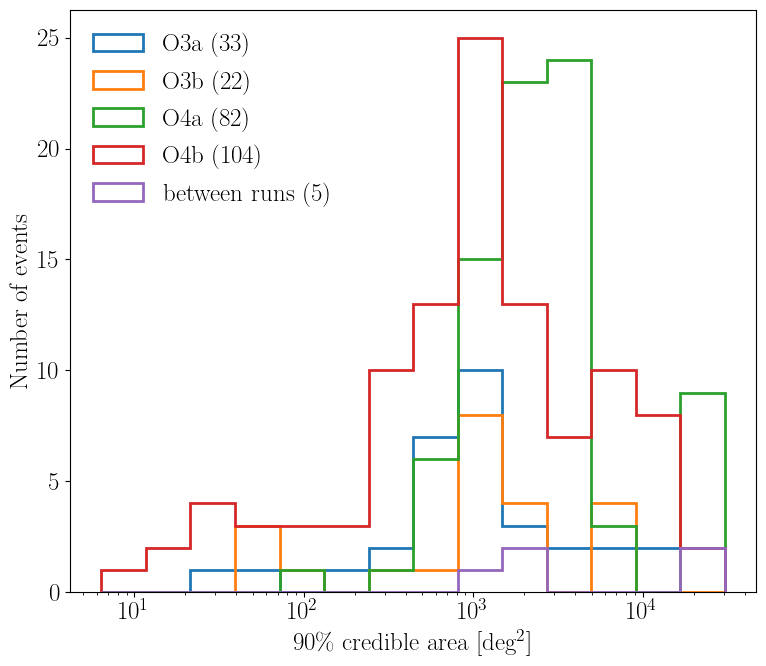

In [16]:
# Sanity check - look at the distribution of the 90% CI sky areas for this sample. 

# Keep only events whose map is a BAYESTAR product (drops S200114f's cWB and S240930du's Bilby fallbacks)

is_bay = PREP['map'].str.lower().str.startswith('bayestar')
A90TAB = PREP.loc[is_bay, ['map', 'a90_native', 'a90_n256']].copy()
A90TAB['run'] = [run_of(T0[s]) for s in A90TAB.index]

# Resampling check: NSIDE 256 should change the area by at most a few per cent
A90TAB['rel_change'] = (A90TAB.a90_n256 - A90TAB.a90_native) / A90TAB.a90_native

print(f'{len(A90TAB)} BAYESTAR maps')
print(A90TAB.groupby('run')['a90_native']
            .describe(percentiles=[0.1, 0.5, 0.9])[['count', 'min', '10%', '50%', '90%', 'max']]
            .round(0).to_string())
print(f"\nNSIDE-256 vs native: median change {A90TAB.rel_change.median():.1e}, "
      f"max |change| {A90TAB.rel_change.abs().max():.1%} ({A90TAB.rel_change.abs().idxmax()})")
print('\nSmallest and largest:')
print(A90TAB.sort_values('a90_native').iloc[[0, 1, 2, -3, -2, -1]][['run', 'map', 'a90_native']].round(1).to_string())

# Histogram by run, log-spaced bins
fig, ax = plt.subplots(figsize=(8, 7))
bins = np.logspace(np.log10(A90TAB.a90_native.min()) - 0.1, np.log10(A90TAB.a90_native.max()) + 0.1, 15)
for run, grp in A90TAB.groupby('run'):
    ax.hist(grp.a90_native, bins=bins, histtype='step', lw=2, label=f'{run} ({len(grp)})')
ax.set_xscale('log')
ax.set_xlabel(r'90\% credible area [deg$^2$]')
ax.set_ylabel('Number of events')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

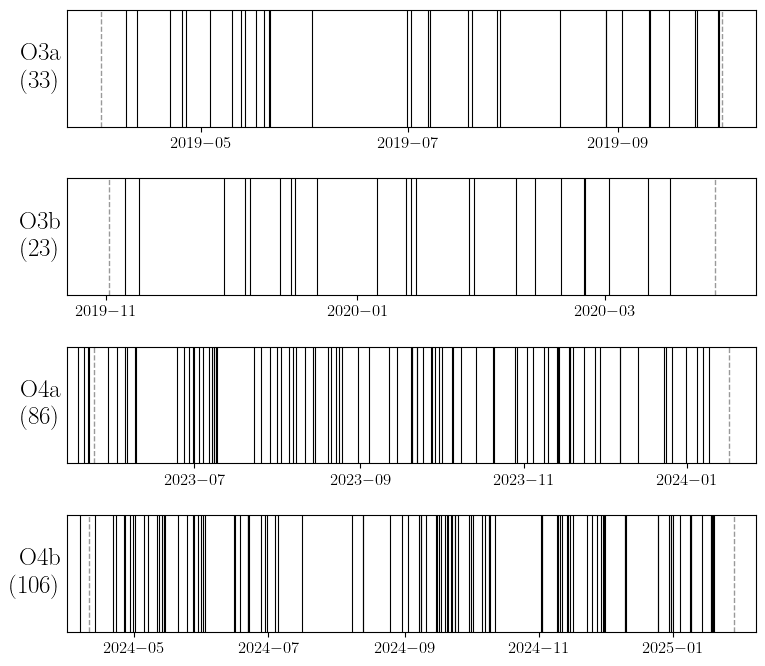

In [17]:
# Another sanity check and for fun, plot when the GW events happen
import matplotlib.dates as mdates

def gps2dt(t):
    return Time(t, format='gps').utc.datetime

PAD = 10 * 86400                      # 10 days either side, so the 5 between-run alerts still appear
kept_t = np.array([T0[s] for s in SID])

fig, axes = plt.subplots(len(RUNS), 1, figsize=(8, 7))
for ax, (run, (t_start, t_end)) in zip(axes, RUNS.items()):
    lo, hi = t_start - PAD, t_end + PAD
    ts = kept_t[(kept_t >= lo) & (kept_t <= hi)]
    ax.vlines([gps2dt(t) for t in ts], 0, 1, color='k', lw=0.8)
    ax.axvline(gps2dt(t_start), color='0.6', ls='--', lw=1)   # official run start/end
    ax.axvline(gps2dt(t_end), color='0.6', ls='--', lw=1)
    ax.set_xlim(gps2dt(lo), gps2dt(hi)); ax.set_ylim(0, 1); ax.set_yticks([])
    ax.set_ylabel(f'{run}\n({len(ts)})', rotation=0, ha='right', va='center')
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 3, 5, 7, 9, 11]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', labelsize=12)
fig.tight_layout()
plt.show()

## Step 4: Spatial matching

We now perform spatial matching between the 43-GW-event sample (GW_SEL) and the GW skymaps.

In [18]:
def cr90_mask(prob):
    '''Minimal pixel set enclosing 90% of the probability (pixels ranked by probability).
    Also returns the number of pixels tied with the last included pixel but left outside.'''
    o = np.argsort(prob)[::-1]
    k = int(np.searchsorted(np.cumsum(prob[o]), 0.9 * prob.sum()) + 1)
    m = np.zeros(prob.size, bool); m[o[:k]] = True
    return m, int(np.sum(prob[~m] == prob[o[k - 1]]))

# SN positions:
SNPIX = {k: ang2pix_nest(NSIDE, v.ra_deg.values, v.dec_deg.values) for k, v in SN.items()}

ANG  = {k: np.zeros((len(GW_SEL), len(v)), bool) for k, v in SN.items()}   # [GW, SN]
A90  = np.zeros(len(GW_SEL))
TIES = np.zeros(len(GW_SEL), int)
for i, s in enumerate(GW_SEL):
    m, TIES[i] = cr90_mask(load(s)['prob'])
    A90[i] = m.mean() * 41252.96
    for k in SN:
        ANG[k][i] = m[SNPIX[k]]

for k, v in SN.items():
    print(f'{k} ({len(v)} SNe): {ANG[k].sum()} GW–SN angular matches; '
          f'GW events with ≥1 match: {ANG[k].any(1).sum()}/{len(GW_SEL)}')

Lasky+ (601 SNe): 2878 GW–SN angular matches; GW events with ≥1 match: 42/43
Yang+ (676 SNe): 3244 GW–SN angular matches; GW events with ≥1 match: 42/43


## Step 5: Temporal matching

We now follow Yang+'s temporal matching procedure:
> *We define the source-rest-frame delay $\Delta t_{\rm rest} = (t^{\rm peak}_{\rm SN} - t_{\rm GW})/(1+z_{\rm SN})$, and adopt the matching criterion $10\,{\rm d} < \Delta t_{\rm rest} < 30\,{\rm d}$. This interval encompasses the observed diversity of the main optical rise of stripped-envelope SNe while remaining restrictive against chance temporal coincidences.*

In [19]:
# --- Step 5.1: temporal matching applied to the Step 4 spatial matches (no distance information) ---
#   Δt_rest = (t_SN^peak − t_GW) / (1 + z_SN),   match if 10 d < Δt_rest < 30 d

DT_MIN, DT_MAX = 10.0, 30.0                                        # rest-frame days

TGW_SEL = np.array([Time(T0[s], format='gps').jd for s in GW_SEL])  # GW trigger times (JD), in the row order of ANG

DT, TIME, SKYTIME = {}, {}, {}
for k, v in SN.items():
    DT[k] = (v.tpeak_jd.values[None, :] - TGW_SEL[:, None]) / (1 + v.z.values[None, :])   # [GW, SN]
    TIME[k] = (DT[k] > DT_MIN) & (DT[k] < DT_MAX)
    SKYTIME[k] = TIME[k] & ANG[k]
    chance = np.sum(TIME[k].sum(1) * A90 / 41252.96)   # expected sky+time pairs if SNe were placed uniformly
    print(f'{k} ({len(v)} SNe):')
    print(f'   time only : {TIME[k].sum()} pairs; GW events with ≥1: {TIME[k].any(1).sum()}/{len(GW_SEL)}')
    print(f'   sky + time: {SKYTIME[k].sum()} pairs (uniform-sky expectation {chance:.1f}); '
          f'GW events with ≥1: {SKYTIME[k].any(1).sum()}; distinct SNe: {SKYTIME[k].any(0).sum()}')

# List every sky+time pair for the stated sample
k = 'Lasky+'
v = SN[k]
PAIRS = pd.DataFrame([(GW_SEL[i], run_of(T0[GW_SEL[i]]), v.IAUID[j], v.type[j], v.z[j], DT[k][i, j])
                        for i, j in zip(*np.where(SKYTIME[k]))],
                       columns=['gw', 'run', 'sn', 'type', 'z', 'dt_rest']).sort_values(['gw', 'dt_rest'])
print(f'\nAll sky + time pairs ({k} sample):')
print(PAIRS.round({'z': 4, 'dt_rest': 1}).to_string(index=False))

Lasky+ (601 SNe):
   time only : 272 pairs; GW events with ≥1: 43/43
   sky + time: 36 pairs (uniform-sky expectation 30.8); GW events with ≥1: 16; distinct SNe: 30
Yang+ (676 SNe):
   time only : 272 pairs; GW events with ≥1: 43/43
   sky + time: 36 pairs (uniform-sky expectation 30.8); GW events with ≥1: 16; distinct SNe: 30

All sky + time pairs (Lasky+ sample):
       gw run         sn     type      z  dt_rest
 S190425z O3a  SN2019cri    SN Ic 0.0500     17.1
 S190425z O3a  SN2019dwa    SN Ic 0.0900     19.3
 S190425z O3a  SN2019dwf   SN IIb 0.0510     20.0
 S190426c O3a  SN2019fyy    SN Ic 0.0362     18.9
S190630ag O3a  SN2019hge   SLSN-I 0.0866     19.9
S190630ag O3a  SN2019mbz  SN Ib/c 0.0270     28.9
 S190718y O3a  SN2019lsq   SLSN-I 0.1400     23.6
 S190718y O3a  SN2019moc SN Ic-BL 0.0558     28.2
S190901ap O3a  SN2019orb    SN Ic 0.0272     15.7
S190901ap O3a  SN2019obh   SN IIb 0.0355     16.9
S190901ap O3a  SN2019pqo   SN IIb 0.0141     20.8
S190901ap O3a  SN2019qwo    SN I

Pull out the GW pairs within 1 day that share an SN (from the Step 5.1 sky + time table)Pull out pairs within one day of one another, because doing it by eye is hard

In [20]:
DT_GW_MAX_H = 24.0

rows = []
for sn, grp in PAIRS.groupby('sn'):
    gws = sorted(grp.gw.unique(), key=lambda s: T0[s])
    for a, b in itertools.combinations(gws, 2):
        dt_h = abs(T0[b] - T0[a]) / 3600
        if dt_h < DT_GW_MAX_H:
            rows.append((sn, grp.type.iloc[0], a, b, dt_h))

CLOSE = pd.DataFrame(rows, columns=['sn', 'type', 'gw_a', 'gw_b', 'dt_hours'])
print(CLOSE.round({'dt_hours': 1}).to_string(index=False))
print('GW events involved:', sorted(set(CLOSE.gw_a) | set(CLOSE.gw_b), key=lambda s: T0[s]))

       sn   type     gw_a     gw_b  dt_hours
SN2019rsq SN IIb S190910d S190910h       7.1
GW events involved: ['S190910d', 'S190910h']


We now replicate the following:
> Among the 43 selected public GW superevents, 10 pairs are separated by less than 5 days and only 3 retain non-zero 3D overlap after incorporating LoS distance information. 

In [21]:
PAIR_DT_MAX = 5.0                                   # days ("separated by less than 5 days")

def los_ci90(mu, sg, q=(0.05, 0.95), ngrid=4001, chunk=2000):
    '''Central 90% interval of p(r|n) ∝ r² N(r; mu, sg), r>0, per pixel. NaN where mu/sg invalid.'''
    mu, sg = np.asarray(mu, float), np.asarray(sg, float)
    out = np.full((len(mu), 2), np.nan)
    good = np.where(np.isfinite(mu) & np.isfinite(sg) & (sg > 0))[0]
    x = np.linspace(0, 1, ngrid)
    for a in range(0, len(good), chunk):
        ii = good[a:a + chunk]
        grid = x[None, :] * (np.maximum(mu[ii], 0) + 10 * sg[ii])[:, None]
        c = np.cumsum(grid**2 * np.exp(-0.5 * ((grid - mu[ii, None]) / sg[ii, None])**2), 1)
        c /= c[:, -1:]
        for kq, qq in enumerate(q):
            out[ii, kq] = grid[np.arange(len(ii)), np.clip((c < qq).sum(1), 0, ngrid - 1)]
    return out

# 1. Pairs of selected GW events separated by < 5 days (GW_SEL is in time order)
GWPAIRS = [(a, b, (T0[b] - T0[a]) / 86400) for a, b in itertools.combinations(GW_SEL, 2)
           if abs(T0[b] - T0[a]) / 86400 < PAIR_DT_MAX]
print(f'{len(GW_SEL)} selected events → {len(GWPAIRS)} pairs separated by < {PAIR_DT_MAX:g} d (paper: 10 of 43)')

# 2. N2D and N3D for each pair (working definition, see text above)
rows = []
for a, b, dt in GWPAIRS:
    da, db = load(a), load(b)
    both = cr90_mask(da['prob'])[0] & cr90_mask(db['prob'])[0]
    px = np.where(both)[0]
    n2d, n3d = len(px), 0
    if 'distmu' in da and 'distmu' in db and n2d:
        ia = los_ci90(da['distmu'][px], da['distsigma'][px])
        ib = los_ci90(db['distmu'][px], db['distsigma'][px])
        ok = np.isfinite(ia[:, 0]) & np.isfinite(ib[:, 0])
        n3d = int(np.sum(ok & (ia[:, 0] <= ib[:, 1]) & (ib[:, 0] <= ia[:, 1])))
    rows.append((a, b, dt * 24, n2d, n2d * 41252.96 / NPIX, n3d))
GWPAIR_TAB = pd.DataFrame(rows, columns=['gw_a', 'gw_b', 'dt_hours', 'N2D', 'A2D_deg2', 'N3D'])
print(GWPAIR_TAB.round({'dt_hours': 1, 'A2D_deg2': 0}).to_string(index=False))
print(f'\npairs with N3D > 0: {(GWPAIR_TAB.N3D > 0).sum()} (paper: 3)')
print('paper N3D: S190910d–h 19,368; S241230ev–S250101k 5,872; S230731an–S230802aq 356')

43 selected events → 10 pairs separated by < 5 d (paper: 10 of 43)
     gw_a      gw_b  dt_hours   N2D  A2D_deg2   N3D
 S190425z  S190426c      31.1     0       0.0     0
 S190510g S190513bm      89.9  2276     119.0     0
S190513bm  S190517h      80.9   288      15.0    84
 S190727h  S190728q      24.7     0       0.0     0
 S190910d  S190910h       7.1 38853    2038.0 23693
 S190923y  S190924h      13.4     0       0.0     0
 S190930s  S190930t       1.0 19152    1005.0     0
S230731an S230802aq      37.7  2940     154.0   822
S240910ci  S240915b     109.6     0       0.0     0
S241230ev  S250101k      25.6  5872     308.0  5872

pairs with N3D > 0: 4 (paper: 3)
paper N3D: S190910d–h 19,368; S241230ev–S250101k 5,872; S230731an–S230802aq 356


In [22]:
# Triplets: one SN matched (sky + time) to both GW events of a < 5 d pair from Step 5.2
M = SKYTIME['Lasky+']
v = SN['Lasky+']
row = {s: i for i, s in enumerate(GW_SEL)}

trip = []
for r in GWPAIR_TAB.itertuples():
    for j in np.where(M[row[r.gw_a]] & M[row[r.gw_b]])[0]:
        trip.append((r.gw_a, r.gw_b, r.dt_hours, r.N3D, v.IAUID[j], v.type[j], v.z[j]))

TRIPLETS = pd.DataFrame(trip, columns=['gw_a', 'gw_b', 'dt_hours', 'N3D', 'sn', 'type', 'z'])
print(f'{len(TRIPLETS)} triplets')
print(TRIPLETS.round({'dt_hours': 1, 'z': 4}).to_string(index=False))

2 triplets
     gw_a     gw_b  dt_hours   N3D        sn     type     z
 S190910d S190910h       7.1 23693 SN2019rsq   SN IIb 0.031
S241230ev S250101k      25.6  5872  SN2025tt SN Ic-BL 0.045


We also identify the same claimed pairs as Supplemental Note 2:

In [23]:
for s in ['S230731an', 'S230802aq', 'S241230ev', 'S250101k']:
    print(s)
    for N, kind, c in CLS[s]:
        print(f"   notice {N:2d} {kind}: " + ', '.join(f"{k}={c.get(k, 0):.3g}" for k in ('BNS', 'NSBH', 'BBH', 'Terrestrial', 'HasMassGap')))

S230731an
   notice  1 PR: BNS=2.98e-32, NSBH=0.000472, BBH=1, Terrestrial=1.11e-16, HasMassGap=0.125
   notice  2 PR: BNS=0, NSBH=0.184, BBH=0.814, Terrestrial=0.00219, HasMassGap=0.053
   notice  3 IN: BNS=0, NSBH=0.184, BBH=0.814, Terrestrial=0.00219, HasMassGap=0.053
   notice  4 UP: BNS=0, NSBH=0.184, BBH=0.814, Terrestrial=0.00219, HasMassGap=0.00293
S230802aq
   notice  1 PR: BNS=3.49e-17, NSBH=0.0623, BBH=0.903, Terrestrial=0.0346, HasMassGap=0.68
   notice  2 PR: BNS=3.49e-17, NSBH=0.0623, BBH=0.903, Terrestrial=0.0346, HasMassGap=0.68
   notice  3 IN: BNS=3.49e-17, NSBH=0.0623, BBH=0.903, Terrestrial=0.0346, HasMassGap=0.68
   notice  4 UP: BNS=3.49e-17, NSBH=0.0623, BBH=0.903, Terrestrial=0.0346, HasMassGap=0.622
S241230ev
   notice  1 PR: BNS=1.03e-26, NSBH=1.08e-11, BBH=0.877, Terrestrial=0.123, HasMassGap=0
   notice  2 PR: BNS=4.85e-25, NSBH=4.3e-23, BBH=0.984, Terrestrial=0.0163, HasMassGap=0
   notice  3 PR: BNS=4.85e-25, NSBH=4.3e-23, BBH=0.984, Terrestrial=0.0163, Ha

## Common distance consistency test

We now replicate the distance compatibility tests and the chance association statistics.

In [24]:
# We reproduce the paper's kernel test, then apply it to the other SN-GW pairs:

def los_params(sid, ra, dec, fname=None):
    '''DISTMU, DISTSIGMA of the line-of-sight ansatz at (ra, dec), native map resolution.'''
    order, ipix, vals = read_map_tiles(local_map(sid, fname or MAPFILE[sid]))
    k = int(order.max())
    px = ang2pix_nest(2**k, [ra], [dec])[0]
    t = np.where(((ipix << (2 * (k - order))) <= px) & (px < ((ipix + 1) << (2 * (k - order)))))[0][0]
    return float(vals['DISTMU'][t]), float(vals['DISTSIGMA'][t])

def combine(m1, s1, m2, s2):
    '''Product of two Gaussian kernels: centre and width.'''
    var = 1.0 / (s1**-2 + s2**-2)
    return var * (m1 / s1**2 + m2 / s2**2), np.sqrt(var)

v = SN['Lasky+']
rows = []
for j in np.where(v.IAUID.isin(['SN2019rsq', 'SN2019pqo', 'SN2019ply', 'SN2019pof', 'SN2019qfi', 'SN2019qwo']))[0]:
    ra, dec, dl = v.ra_deg[j], v.dec_deg[j], v.dl_mpc[j]
    for src, fnames in (('BAYESTAR', (None, None)),
                       ('LALInference', ('LALInference.multiorder.fits', 'LALInference.multiorder.fits'))):
        md, sd = los_params('S190910d', ra, dec, fnames[0])
        mh, sh = los_params('S190910h', ra, dec, fnames[1])
        mc, sc = combine(md, sd, mh, sh)
        rows.append((v.IAUID[j], v.type[j], dl, src, md, sd, (dl - md) / sd, mh, sh, (dl - mh) / sh,
                     mc, sc, (dl - mc) / sc, (md - mh) / np.hypot(sd, sh)))
CDIST = pd.DataFrame(rows, columns=['sn', 'type', 'dl', 'maps', 'mu_d', 'sig_d', 'z_d', 'mu_h', 'sig_h', 'z_h',
                                    'mu_comb', 'sig_comb', 'z_comb', 'centres_sep'])
print(CDIST.round(2).to_string(index=False))

       sn     type     dl         maps     mu_d  sig_d   z_d   mu_h  sig_h   z_h  mu_comb  sig_comb  z_comb  centres_sep
SN2019ply   SN IIb  97.74     BAYESTAR   261.25 123.57 -1.32 214.18  94.70 -1.23   231.60     75.16   -1.78         0.30
SN2019ply   SN IIb  97.74 LALInference   274.64 135.70 -1.30 218.34  87.73 -1.37   234.93     73.68   -1.86         0.35
SN2019pqo   SN IIb  63.28     BAYESTAR   689.65 272.65 -2.30 145.66  67.15 -1.23   176.77     65.20   -1.74         1.94
SN2019pqo   SN IIb  63.28 LALInference     7.28  55.54  1.01 124.69  64.99 -0.94    56.83     42.22    0.15        -1.37
SN2019pof   SN IIb  69.49     BAYESTAR   160.49 149.44 -0.61 233.06 101.14 -1.62   210.26     83.76   -1.68        -0.40
SN2019pof   SN IIb  69.49 LALInference -1194.55 351.41  3.60 223.85  97.77 -1.58   121.95     94.19   -0.56        -3.89
SN2019qwo    SN Ib 206.15     BAYESTAR   451.28 197.96 -1.24 149.81  68.93  0.82   182.41     65.10    0.36         1.44
SN2019qwo    SN Ib 206.15 LALInf

In [25]:
# We now analytically check the chance-probability for consistency
TAU_D   = 7.1 / 24                                               # observed separation, days
T_SPAN  = Time('2025-01-28').jd - Time('2019-04-01').jd          # paper's calendar baseline (~2130 d)
T_OBS   = sum((b - a) for a, b in RUNS.values()) / 86400          # O3a+O3b+O4a+O4b observing span (~860 d)
p_t_cal = 2 * TAU_D / T_SPAN - (TAU_D / T_SPAN)**2
p_t_obs = 2 * TAU_D / T_OBS
print(f'T_span = {T_SPAN:.0f} d, T_obs = {T_OBS:.0f} d')
print(f'P(|Δt| < 7.1 h): calendar baseline {p_t_cal:.2e}; observing time only {p_t_obs:.2e}')
print(f'implied spatial fraction from the paper: f = 7.6e-5 / {p_t_cal:.2e} = {7.6e-5 / p_t_cal:.2f}')

# 90% region pixels and kernel parameters per selected event (indices sorted, so pairs intersect quickly)
REG = {}
for s in GW_SEL:
    d = load(s)
    px = np.where(cr90_mask(d['prob'])[0])[0]
    REG[s] = (px, d['distmu'][px], d['distsigma'][px]) if 'distmu' in d else (px, None, None)

def n2d_n3d_kernel(a, b):
    '''Paper's definition: N2D = common 90% pixels; N3D = those with |mu1 - mu2| < sigma1 + sigma2.'''
    pa, ma, sa = REG[a]; pb, mb, sb = REG[b]
    _, ia, ib = np.intersect1d(pa, pb, assume_unique=True, return_indices=True)
    if ma is None or mb is None:
        return len(ia), 0
    ok = np.isfinite(ma[ia]) & np.isfinite(mb[ib]) & np.isfinite(sa[ia]) & np.isfinite(sb[ib])
    return len(ia), int(np.sum(ok & (np.abs(ma[ia] - mb[ib]) < sa[ia] + sb[ib])))

# Check 5: paper's three pairs with the paper's N3D definition (only those whose events are in GW_SEL)
for (a, b), paper in {('S190910d', 'S190910h'): 19368, ('S241230ev', 'S250101k'): 5872,
                      ('S230731an', 'S230802aq'): 356}.items():
    if a in REG and b in REG:
        print(f'{a}–{b}: N2D, N3D (kernel def) = {n2d_n3d_kernel(a, b)}; paper N3D = {paper}')

# Checks 1–3: spatial fraction f over all pairs of selected events, and implied probabilities
pairs = list(itertools.combinations(GW_SEL, 2))
passed = np.array([min(n2d_n3d_kernel(a, b)) > 100 for a, b in pairs])
f = passed.mean()
print(f'\n{len(GW_SEL)} events, {len(pairs)} pairs: fraction with N2D>100 and N3D>100, f = {f:.3f}')
print(f'per-pair P(7.1 h, 3-D): calendar {p_t_cal * f:.1e} (paper 7.6e-5); observing time {p_t_obs * f:.1e}')
for label, p in (('calendar', p_t_cal * f), ('observing time', p_t_obs * f)):
    lam = len(pairs) * p
    print(f'whole sample, {label}: expected chance pairs {lam:.3f}, P(≥1) = {1 - np.exp(-lam):.3f}')

T_span = 2129 d, T_obs = 860 d
P(|Δt| < 7.1 h): calendar baseline 2.78e-04; observing time only 6.88e-04
implied spatial fraction from the paper: f = 7.6e-5 / 2.78e-04 = 0.27
S190910d–S190910h: N2D, N3D (kernel def) = (38853, 19373); paper N3D = 19368
S241230ev–S250101k: N2D, N3D (kernel def) = (5872, 5872); paper N3D = 5872
S230731an–S230802aq: N2D, N3D (kernel def) = (2940, 0); paper N3D = 356

43 events, 903 pairs: fraction with N2D>100 and N3D>100, f = 0.312
per-pair P(7.1 h, 3-D): calendar 8.7e-05 (paper 7.6e-5); observing time 2.1e-04
whole sample, calendar: expected chance pairs 0.078, P(≥1) = 0.075
whole sample, observing time: expected chance pairs 0.194, P(≥1) = 0.176


In [26]:
# We now check the probability of 2GW events (P2GW) in detail, replicating the MC simulation:
TAU_D = 7.1 / 24                                   # days
pairs = list(itertools.combinations(GW_SEL, 2))
NN = np.array([n2d_n3d_kernel(a, b) for a, b in pairs])# (N2D, N3D) per pair
passes = (NN[:, 0] > 100) & (NN[:, 1] > 100)
f = passes.mean()

# Analytic
p_close = 2 * TAU_D / T_SPAN - (TAU_D / T_SPAN)**2
P_analytic = p_close * f

# Monte Carlo, as in the paper: random pair, independent uniform times over T_SPAN
rng = np.random.default_rng(1)
N_MC = 10**6
k  = rng.integers(len(pairs), size=N_MC)
t1 = rng.uniform(0, T_SPAN, N_MC)
t2 = rng.uniform(0, T_SPAN, N_MC)
hit = (np.abs(t1 - t2) < TAU_D) & passes[k]
P_mc = hit.mean()
P_mc_err = np.sqrt(P_mc * (1 - P_mc) / N_MC)

print(f'{len(GW_SEL)} events → {len(pairs)} pairs; {passes.sum()} pass N2D>100 and N3D>100  →  f = {f:.3f}')
print(f'P(|Δt| < 7.1 h) = 2τ/T − (τ/T)² = {p_close:.3e}')
print(f'P2GW analytic   = {p_close:.3e} × {f:.3f} = {P_analytic:.2e}')
print(f'P2GW Monte Carlo ({N_MC:.0e} draws) = {P_mc:.2e} ± {P_mc_err:.1e}   ({hit.sum()} hits)')
print('P2GW paper      = 7.6e-05')

43 events → 903 pairs; 282 pass N2D>100 and N3D>100  →  f = 0.312
P(|Δt| < 7.1 h) = 2τ/T − (τ/T)² = 2.779e-04
P2GW analytic   = 2.779e-04 × 0.312 = 8.68e-05
P2GW Monte Carlo (1e+06 draws) = 8.20e-05 ± 9.1e-06   (82 hits)
P2GW paper      = 7.6e-05


In [27]:
# Finally, we calculate the SN chance coincidence, replicating the result of Yang+, and investigating the result of varyig the time window
NPIX256 = 12 * 256**2
R = {'SE': 2.2e-5, 'IIb': 0.8e-5}# From Yang+

def p_chance(rate, n_pix, dmin, dmax, dt_days):
    V = n_pix / NPIX256 * 4 * np.pi / 3 * (dmax**3 - dmin**3)
    n = rate * V * dt_days / 365.25
    return V, n, 1 - np.exp(-n)

cases = [('paper: N3D, 1σ combined shell, Δt = 10 d', 19368, 134.6, 277.9, 10),
         ('Δt = 20 d (search window)',                19368, 134.6, 277.9, 20),
         ('N2D volume (no distance used in search)',  38853, 134.6, 277.9, 10),
         ('N2D volume and Δt = 20 d',                 38853, 134.6, 277.9, 20)]
rows = []
for label, npix, d0, d1, dt in cases:
    for k, rate in R.items():
        V, n, p = p_chance(rate, npix, d0, d1, dt)
        rows.append((label, k, V, n, p))
print(pd.DataFrame(rows, columns=['case', 'SN class', 'V [Mpc^3]', 'N_exp', 'P(>=1)'])
        .to_string(index=False, float_format=lambda x: f'{x:.3g}'))

                                    case SN class  V [Mpc^3]  N_exp  P(>=1)
paper: N3D, 1σ combined shell, Δt = 10 d       SE   1.96e+06   1.18   0.693
paper: N3D, 1σ combined shell, Δt = 10 d      IIb   1.96e+06   0.43   0.349
               Δt = 20 d (search window)       SE   1.96e+06   2.36   0.906
               Δt = 20 d (search window)      IIb   1.96e+06   0.86   0.577
 N2D volume (no distance used in search)       SE   3.94e+06   2.37   0.907
 N2D volume (no distance used in search)      IIb   3.94e+06  0.862   0.578
                N2D volume and Δt = 20 d       SE   3.94e+06   4.74   0.991
                N2D volume and Δt = 20 d      IIb   3.94e+06   1.72   0.822
